[<< Sommaire Sudoku](./README.md) | [Précédent : Sudoku-19-Lean-Propagation <<](./Sudoku-19-Lean-Propagation-Lean.ipynb)

# Sudoku-20 : La hiérarchie de difficulté des corpus, mesurée

> **[RECHERCHE / MÉTHODE]** Les noms des fichiers de puzzles (`Easy51`, `hardest`, `top95`) affirment une hiérarchie de difficulté. Ce carnet la **mesure** : unicité des solutions par dénombrement, part résolue par propagation seule, effort de recherche, irrédundance des indices.

Ce carnet est la narration pédagogique de l'organe d'audit [`scripts/sudoku/core/corpus.py`](https://github.com/jsboige/CoursIA/blob/main/scripts/sudoku/core/corpus.py), introduit par l'issue [#22715](https://github.com/jsboige/CoursIA/issues/22715). Il n'écrit **aucun solveur** : la propagation et la recherche MRV viennent de l'organe canonique de la série (`solvers.py`, présenté dans [Sudoku-07](Sudoku-07-Norvig-Python.ipynb)) ; ce que ce carnet ajoute, c'est la lecture des mesures.

## Objectifs d'apprentissage

- Distinguer « une solution trouvée » et « une solution unique » — et comprendre pourquoi seul le dénombrement plafonné les sépare ;
- Lire la ligne de partage **propagation seule / recherche** : ce que le solveur déduit sans jamais deviner ;
- Mesurer une hiérarchie de difficulté annoncée par des noms de fichiers, et rencontrer son contrôle négatif (le corpus `hardest` n'est pas homogène) ;
- Définir l'**irrédundance** d'un jeu d'indices — et pourquoi elle n'est pas la **minimalité**.

**Prérequis** : [Sudoku-07](Sudoku-07-Norvig-Python.ipynb) (propagation de Norvig). **Durée** : ~25 min. Python uniquement (`numpy`, `matplotlib`).

## 1. Trois corpus, deux notations

La série consomme trois fichiers de `Puzzles/` : `Sudoku_Easy51.txt` (51 grilles), `Sudoku_hardest.txt` (11) et `Sudoku_top95.txt` (95) — 157 grilles au total. Leurs noms affirment une difficulté croissante ; rien d'autre ne la certifie. Détail concret : les fichiers n'écrivent pas les cases vides de la même façon — `Easy51` utilise le chiffre `0`, les deux autres le point `.`. L'organe de lecture (`corpus.parse_puzzle`) accepte les deux notations : un instrument qui sait lire les deux ne peut pas confondre un corpus avec un autre.

In [1]:
# Resolution de l'organe : import par chemin de fichier, comme le font les
# tests de la serie (la chaine de paquet core/__init__.py charge torch, la
# docstring de corpus.py documente ce contournement).
from pathlib import Path
import sys

candidates = [Path.cwd(), *Path.cwd().parents]
root = next(p for p in candidates if (p / "scripts" / "sudoku" / "core" / "corpus.py").exists())
sys.path.insert(0, str(root / "scripts" / "sudoku" / "core"))

import corpus

corpora = {}
for name in corpus.CORPUS_FILES:
    corpora[name] = corpus.load_corpus(corpus.PUZZLE_DIR / name)
    text = (corpus.PUZZLE_DIR / name).read_text(encoding="utf-8").splitlines()
    first = next(line for line in text if line.strip())
    print(f"{name:<22} {len(corpora[name]):>3} grilles | premiere ligne : {first[:24]}...")

Sudoku_Easy51.txt       51 grilles | premiere ligne : 902005403100063025508407...
Sudoku_hardest.txt      11 grilles | premiere ligne : 85...24..72......9..4......
Sudoku_top95.txt        95 grilles | premiere ligne : 4.....8.5.3..........7.....


### Lecture du résultat

Les trois effectifs — **51, 11 et 95 grilles** — et les deux notations sont visibles sur la première ligne de chaque fichier : celle d'`Easy51` mêle chiffres et `0`, celles d'`hardest` et `top95` mêlent chiffres et `.`. La hiérarchie que ces noms annoncent est, à ce stade, une **convention de nommage** ; la suite du carnet la transforme en propriété mesurée.

## 2. « Soluble » n'est pas « à solution unique »

Un solveur rend **la première solution qu'il trouve** — la même sortie qu'il existe une solution ou mille. Ce qui distingue un puzzle d'une sous-détermination, c'est le **nombre** de solutions, et l'organe le mesure par dénombrement exhaustif **plafonné** : `count_solutions(grille, 2)` rend 1 s'il existe exactement une solution, et 2 dès qu'il en existe au moins deux. Le plafond est ce qui rend la question tractable : on n'énumère pas mille solutions pour savoir qu'il y en a deux.

In [2]:
import numpy as np

empty = np.zeros(81, dtype=np.int64)  # grille sans aucun indice
first_easy = corpora["Sudoku_Easy51.txt"][0]

print("grille sans indice    -> solutions (plafond 2) :", corpus.count_solutions(empty, 2))
print("premier puzzle Easy51 -> solutions (plafond 2) :", corpus.count_solutions(first_easy, 2))

grille sans indice    -> solutions (plafond 2) : 2
premier puzzle Easy51 -> solutions (plafond 2) : 1


### Lecture du résultat

La grille sans indice rend **2** : elle est soluble (un solveur en trouve une) mais son dénombrement sature dès la deuxième solution — c'est la définition opérationnelle d'une sous-détermination. Le premier puzzle d'`Easy51` rend **1** : exactement une solution, c'est un puzzle au sens propre. Un solveur qui affiche « une » solution affiche la même chose dans les deux cas ; **seul le comptage plafonné les distingue**.

## 3. Propagation seule contre recherche

`corpus.search_effort(grille)` compte les décisions de backtracking — les couples (case, chiffre) essayés — pour atteindre la première solution. **0 décision** signifie que la propagation seule (candidats nus et candidats cachés, la brique de [Sudoku-07](Sudoku-07-Norvig-Python.ipynb)) a suffi : aucun devin, aucune hypothèse, de la déduction pure. C'est la lecture « solveur humain » d'une grille. L'audit complet des trois corpus tient en un appel.

In [3]:
import time

t0 = time.perf_counter()
audits = corpus.audit_all(reduce_clues=False)
duration = time.perf_counter() - t0

print(corpus.format_summary(audits))
print(f"\naudit complet des trois corpus : {duration:.2f} s")

corpus                    n  invalides  non uniques   propagation seule  pire effort
------------------------------------------------------------------------------------
Sudoku_Easy51.txt        51          0            0           41 (80 %)            7
Sudoku_hardest.txt       11          0            0            1 (9 %)           21
Sudoku_top95.txt         95          0            0            0 (0 %)          446

audit complet des trois corpus : 1.42 s


### Lecture du résultat

La part « propagation seule » décroît strictement — **80 %, 9 %, 0 %** — et le pire effort de recherche croît strictement — **7, 21 puis 446 décisions**. Les deux ordres sont monotones et concordants : la hiérarchie des noms de fichiers est une **propriété mesurée** du corpus, pas une convention. Et la certification des 157 grilles coûte moins de deux secondes — mesurer la difficulté est bon marché, la supposer ne coûte rien, mais ne prouve rien.

In [4]:
for name, audit in audits.items():
    decisions = sorted(r["decisions"] for r in audit["records"])
    clues = sorted(r["clues"] for r in audit["records"])
    print(
        f"{name:<22} propagation seule : {decisions.count(0):>2}/{audit['count']:<2}"
        f" | mediane : {decisions[len(decisions)//2]:>3} decisions"
        f" | pire : {decisions[-1]:>3}"
        f" | indices : {clues[0]} a {clues[-1]}"
    )

Sudoku_Easy51.txt      propagation seule : 41/51 | mediane :   0 decisions | pire :   7 | indices : 22 a 45
Sudoku_hardest.txt     propagation seule :  1/11 | mediane :   8 decisions | pire :  21 | indices : 22 a 28
Sudoku_top95.txt       propagation seule :  0/95 | mediane :  39 decisions | pire : 446 | indices : 17 a 26


### Lecture du résultat

La médiane et le maximum racontent la même histoire à deux échelles : la moitié d'`Easy51` se résout **sans aucune décision** (médiane 0), celle de `top95` en demande déjà **39** — davantage que le *pire* cas d'`Easy51` (7). Les effectifs d'indices se recouvrent largement (22 à 45 pour `Easy51`, 17 à 26 pour `top95`) : le nombre d'indices n'est donc pas, à lui seul, ce que « difficile » mesure ici — deux grilles de 22 indices peuvent tomber de part et d'autre de la ligne de partage.

## 4. Le contrôle négatif : « hardest » n'est pas homogène

Une hiérarchie de corpus ne dit rien de chaque grille prise individuellement. Le contrôle négatif consiste à chercher, dans le corpus « le plus dur après `top95` », une grille qui se résoudrait par propagation seule — un contre-exemple à l'homogénéité du corpus.

In [5]:
for name in ("Sudoku_hardest.txt", "Sudoku_top95.txt"):
    puzzles = corpora[name]
    indices = [i + 1 for i, p in enumerate(puzzles) if corpus.propagation_only(p)]
    print(f"{name:<22} propagation seule : {indices if indices else 'aucune'}")

anomaly = next(p for p in corpora["Sudoku_hardest.txt"] if corpus.propagation_only(p))
print("l'intrus de hardest :", int((anomaly != 0).sum()), "indices")

Sudoku_hardest.txt     propagation seule : [5]


Sudoku_top95.txt       propagation seule : aucune
l'intrus de hardest : 22 indices


### Lecture du résultat

`top95` ne contient **aucune** grille de propagation seule — le corpus est homogène. Mais `hardest` en contient exactement **une** : la grille n° **5**, avec 22 indices. Aucun devin n'est nécessaire pour la terminer. Le nom du fichier est une convention d'échantillon ; l'homogénéité serait une propriété — et elle est fausse pour `hardest`. La hiérarchie tient **au niveau du corpus** (les parts 80 % / 9 % / 0 %), pas garantie grille par grille.

## 5. Irrédundance des indices

Un jeu d'indices est **irrédundant** si aucun indice ne peut être retiré sans détruire l'unicité de la solution. L'organe (`corpus.minimal_clue_set`) teste les retraits un par un, dans l'ordre des cases, et ne conserve un retrait que si la grille réduite garde **exactement une** solution, identique à l'originale — le critère est l'unicité, pas « une solution trouvée ». Le résultat est irrédundant **à l'ordre de suppression près** ; il n'est pas forcément *minimal* en cardinal (cela exigerait une recherche exhaustive sur les sous-ensembles). Le vocabulaire est exact : irrédundant n'est pas minimal.

In [6]:
import solvers

grid0, retired0 = corpus.minimal_clue_set(first_easy)
kept0 = int((first_easy != 0).sum())
print(f"Easy51 no 1 : {kept0} indices -> {kept0 - len(retired0)} conserves ({len(retired0)} redondants)")

second = corpora["Sudoku_Easy51.txt"][7]
grid7, retired7 = corpus.minimal_clue_set(second)
kept7 = int((second != 0).sum())
print(f"Easy51 no 8 : {kept7} indices -> {kept7 - len(retired7)} conserves ({len(retired7)} redondants)")

unique_reduced = corpus.count_solutions(grid0, 2) == 1
same_solution = np.array_equal(solvers.solve_sudoku(grid0), solvers.solve_sudoku(first_easy))
print("grille reduite : solution unique =", unique_reduced, "| meme solution que l'originale =", same_solution)

Easy51 no 1 : 45 indices -> 24 conserves (21 redondants)
Easy51 no 8 : 26 indices -> 24 conserves (2 redondants)
grille reduite : solution unique = True | meme solution que l'originale = True


### Lecture du résultat

Les deux grilles du même corpus « facile » aboutissent au **même cardinal 24** par des chemins très différents : 45 indices dont 21 redondants pour la première, 26 indices dont 2 seulement pour la huitième. La contre-vérification confirme que la grille réduite détermine toujours **une** solution unique, identique à celle de la grille complète — l'irrédundance n'a rien perdu. **Limite déclarée** : la réduction dénombre les solutions de chaque grille candidate ; sur `top95` (pire cas 446 décisions) ce coût explose, la démonstration reste donc sur `Easy51`.

## 6. La hiérarchie, rendue visible

Les deux mesures du carnet — part de propagation seule et pire effort de recherche — dessinent la même hiérarchie dans deux unités différentes. Une échelle linéaire pour la première, une échelle logarithmique pour la seconde : l'écart 7 → 446 couvre deux ordres de grandeur.

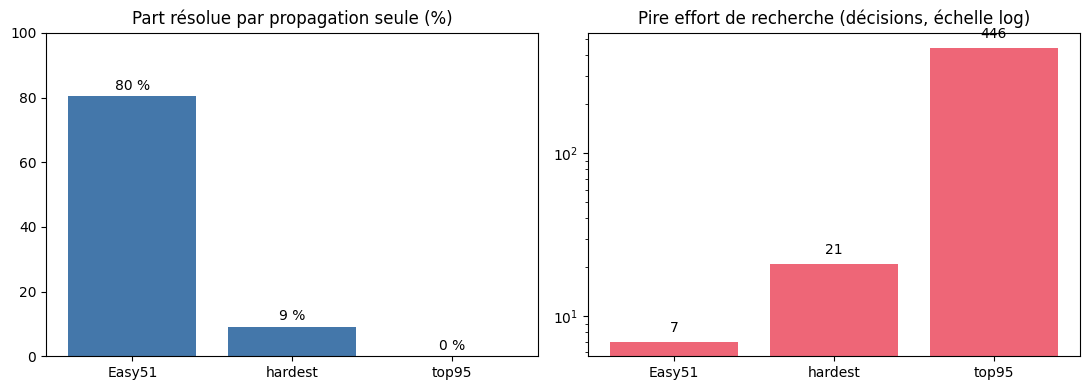

In [7]:
import matplotlib.pyplot as plt

names = list(audits)
labels = [n.replace("Sudoku_", "").replace(".txt", "") for n in names]
prop_share = [100 * audits[n]["propagation_only"] / audits[n]["count"] for n in names]
max_effort = [audits[n]["max_decisions"] for n in names]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.bar(labels, prop_share, color="#4477aa")
ax1.set_title("Part résolue par propagation seule (%)")
ax1.set_ylim(0, 100)
for i, value in enumerate(prop_share):
    ax1.text(i, value + 2, f"{value:.0f} %", ha="center")
ax2.bar(labels, max_effort, color="#ee6677")
ax2.set_title("Pire effort de recherche (décisions, échelle log)")
ax2.set_yscale("log")
for i, value in enumerate(max_effort):
    ax2.text(i, value * 1.15, str(value), ha="center")
fig.tight_layout()
plt.show()

### Lecture du résultat

Les deux panneaux descendent dans le même ordre : la part de propagation seule s'effondre de 80 % à 0 % pendant que l'effort maximal grimpe de 7 à 446 décisions. C'est la même hiérarchie vue par deux instruments — l'un compte ce que la déduction suffit à faire, l'autre ce que la recherche doit payer.

## 7. Exercices

Trois exercices, du plus mécanique au plus conceptuel. Les stubs s'exécutent sans erreur : complétez-les.

In [8]:
# Exercice 1 -- Détecter la notation d'un corpus.
# Les deux notations coexistent (0 pour Easy51, . pour les deux autres).
# Ecrire notation_vide(lignes) qui rend '0' ou '.' selon le caractere vide
# reellement utilise, SANS utiliser corpus.parse_puzzle (c'est l'exercice).
# Indice : dans une notation, le caractere vide apparait de tres nombreuses
# fois par ligne ; un chiffre donne n'apparait jamais comme indice.
# Etape 1 : observer une ligne de chaque corpus ; Etape 2 : decider ;
# Etape 3 : verifier que la fonction rend le meme resultat pour chaque ligne
# d'un meme corpus.
def notation_vide(lignes):
    # TODO etudiant
    return None

print("Exercice 1 a completer")

Exercice 1 a completer


In [9]:
# Exercice 2 -- Jusqu'ou peut-on appauvrir un puzzle ?
# Partir de la grille reduite de Easy51 no 1 (24 indices, section 5). Retirer
# un indice de plus, puis mesurer : la grille garde-t-elle une solution
# unique ? Combien d'indices supplémentaires peut-on retirer (dans l'ordre
# des cases) avant que count_solutions rende 2 ?
# Indice : la boucle de minimal_clue_set est le modele -- la difference est
# qu'ici on ne s'arrete pas a la premiere grille non unique : on cherche la
# derniere grille qui l'etait encore, puis la premiere qui ne l'est plus.
# TODO etudiant
print("Exercice 2 a completer")

Exercice 2 a completer


In [10]:
# Exercice 3 -- L'invariant de la hierarchie, en une fonction.
# La hierarchie mesuree tient dans deux ordres monotones au sens large :
# part de propagation seule decroissante (>= entre voisins), pire effort
# croissant (<= entre voisins). Ecrire invariant_hierarchie(audits) qui rend
# True ssi les deux ordres tiennent, False des qu'un ordre s'inverse.
# Etape 1 : extraire les deux series dans l'ordre des corpus ; Etape 2 :
# comparer chaque paire de voisins ; Etape 3 : verifier sur audits que le
# resultat est True, puis l'inverser artificiellement (echanger deux corpus)
# pour verifier qu'il rend bien False.
def invariant_hierarchie(audits):
    # TODO etudiant
    return None

print("Exercice 3 a completer")

Exercice 3 a completer


## 8. Ce que ce carnet a établi

- **Soluble n'est pas unique** : le dénombrement plafonné à 2 est le seul instrument de la distinction (section 2) ;
- **La hiérarchie est mesurée, pas nommée** : parts de propagation seule 80 % / 9 % / 0 % et pires efforts 7 / 21 / 446, deux ordres monotones concordants (section 3) ;
- **Elle est réfutable** : elle tombe dès qu'un des deux ordres s'inverse à la prochaine mesure — corpus modifié ou organ modifié. C'est le sujet de l'exercice 3 ;
- **Elle est corpus, pas garantie grille par grille** : `hardest` porte une grille de propagation seule (section 4) ;
- **Irrédundant n'est pas minimal** : la réduction préserve l'unicité à chaque retrait, sans chercher le minimum en cardinal (section 5).

**Limites déclarées** : l'irrédundance n'est mesurée que sur `Easy51` (le dénombrement sur `top95` explose) ; les valeurs absolues d'effort sont celles de l'organe (`solvers.py`, heuristique MRV) — un autre ordre d'exploration donnerait d'autres valeurs absolues, les ordres eux-mêmes restant à mesurer.